In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
from matplotlib.colors import ListedColormap
%matplotlib inline
warnings.filterwarnings('ignore')

# for plotting
cmap2 = ListedColormap(['r', 'k'])
cmap4 = ListedColormap(['k', 'r', 'g', 'b'])

### Mice Protein Dataset

In [2]:
import numpy as np
%matplotlib inline

import pandas as pd

data = pd.read_csv('Data_Cortex_Nuclear.csv', header=0).iloc[:, 1:78].apply(
    pd.to_numeric, errors='coerce'
).fillna(0).to_numpy()
classes = np.genfromtxt('Data_Cortex_Nuclear.csv',delimiter=',',
                        skip_header=1,usecols=range(78,81),dtype=None)

Separate target and background datasets:
* Target = mice that received shock therapy. Some have Down Syndrome, others don't, but it is assumed this label is not known *a priori*
* Background = mice that have not been stimulated by shock therapy, and do not have Down Syndrome. 

In [3]:
target_idx_A = np.where((classes[:,-1]=='S/C') & (classes[:,-2]=='Saline') & (classes[:,-3]=='Control'))[0]
target_idx_B = np.where((classes[:,-1]=='S/C') & (classes[:,-2]=='Saline') & (classes[:,-3]=='Ts65Dn'))[0]

sub_group_labels = len(target_idx_A)*[0] + len(target_idx_B)*[1]
target_idx = np.concatenate((target_idx_A,target_idx_B))                                                                          
data = np.genfromtxt('Data_Cortex_Nuclear.csv', delimiter=',',
                     skip_header=1, usecols=range(1, 78),
                     filling_values=0, invalid_raise=False)
target = data[target_idx]
target = (target-np.mean(target,axis=0)) / np.std(target,axis=0) # standardize the dataset

background_idx = np.where((classes[:,-1]=='C/S') & (classes[:,-2]=='Saline') & (classes[:,-3]=='Control'))
# background_idx = np.where((classes[:,-1]==b'C/S') & (classes[:,-2]==b'Saline') & (classes[:,-3]==b'Ts65Dn'))
background = data[background_idx]
background = (background-np.mean(background,axis=0)) / np.std(background,axis=0) # standardize the dataset
labels = len(background)*[0] + len(target)*[1]
data = np.concatenate((background, target))

# Comparing cPCA to Other Dimensionality Reduction Techniques

### PCA and cPCA

(PCA corresponds to the first column, since it is equivalent to cPCA with $\alpha=0$)

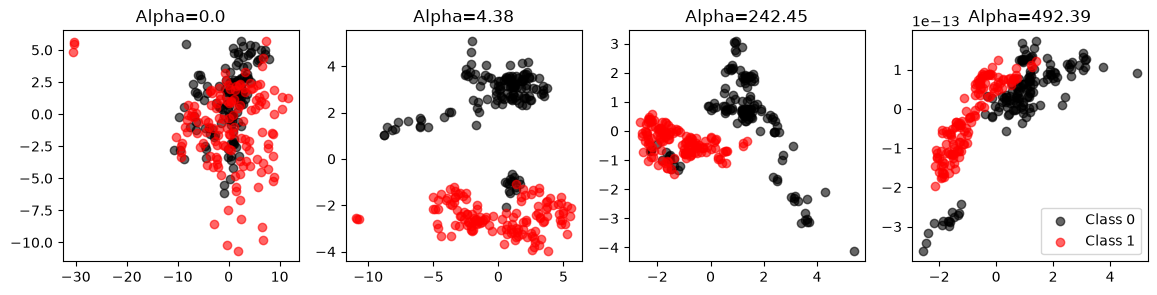

In [4]:
from contrastive import CPCA
mdl = CPCA()

projected_data = mdl.fit_transform(target, background, plot=True, active_labels=sub_group_labels)

PCA is unable to find subgroups of interest in the mice data,  while cPCA separates 2 subgroups with an appropriate (and automatically discovered) value of $\alpha$. 

### Linear Discriminant Analysis (LDA)

Note: because LDA returns at most $c-1$ components, where $c$ is the number of classes in the data, in this case, the target data is projected onto exactly 1 dimension (the x-dimension). For ease of visualization, we assign a random value to the y-dimension of each data point, and plot them in 2 dimensions.

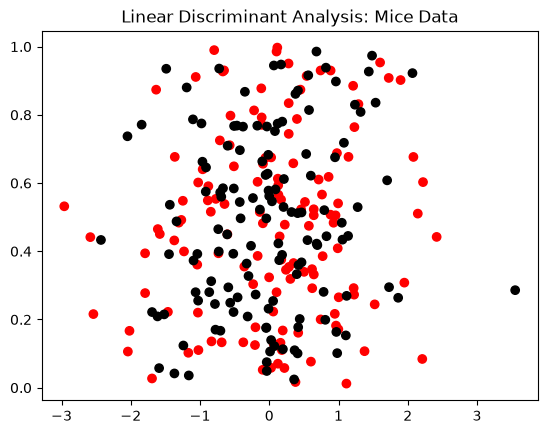

In [5]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
mdl = LDA()

projected_data = mdl.fit(data, labels).transform(target)
random_y_values = np.random.random(size=projected_data.shape)
plt.figure()
plt.scatter(projected_data, random_y_values, c=sub_group_labels, cmap=cmap2)
plt.title('Linear Discriminant Analysis: Mice Data')

p1 = projected_data.copy()
y1 = random_y_values.copy()

### Quadratic Discriminant Analysis (QDA)

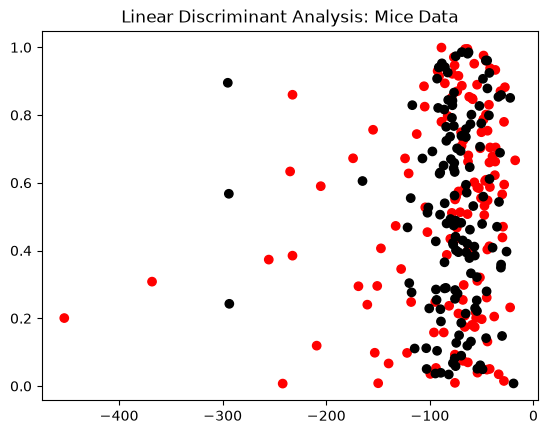

In [6]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
mdl = QDA(reg_param=0.1)

projected_data = mdl.fit(data, labels).predict_log_proba(target)[:,0]
random_y_values = np.random.random(size=projected_data.shape)
plt.figure()
plt.scatter(projected_data, random_y_values, c=sub_group_labels, cmap=cmap2)
plt.title('Linear Discriminant Analysis: Mice Data')

p2 = projected_data.copy()
y2 = random_y_values.copy()

### Supervised PCA

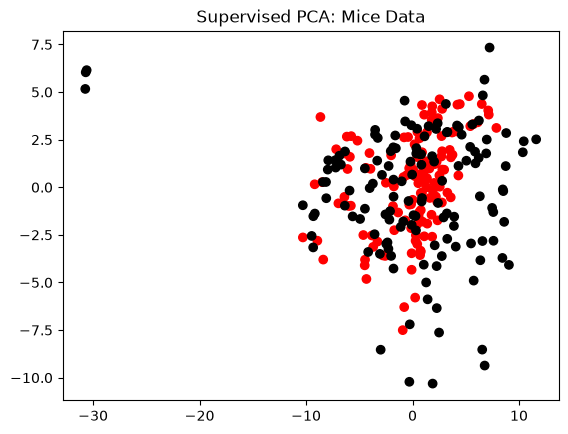

In [7]:
from supervised import SupervisedPCAClassifier

mdl = SupervisedPCAClassifier(n_components=2)

projected_data = mdl.fit(data, labels).get_transformed_data(target)
plt.figure()
plt.scatter(*projected_data.T, c=sub_group_labels, cmap=cmap2)
plt.title('Supervised PCA: Mice Data')

p3 = projected_data.copy()

### Independent Component Analysis

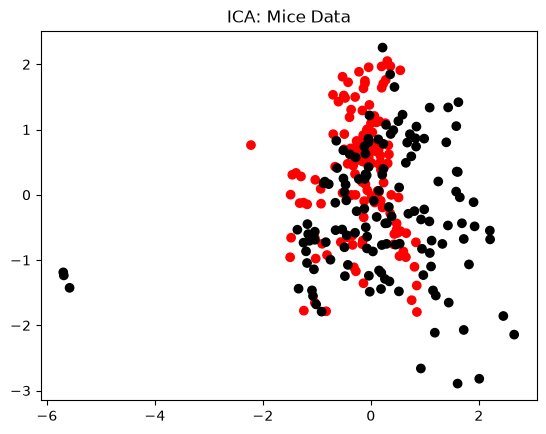

In [8]:
from sklearn.decomposition import FastICA as ICA

mdl = ICA(n_components=2)

projected_data = mdl.fit_transform(target)
plt.figure()
plt.scatter(*projected_data.T, c=sub_group_labels, cmap=cmap2)
plt.title('ICA: Mice Data')

p4 = projected_data.copy()

### Principal Component Pursuit

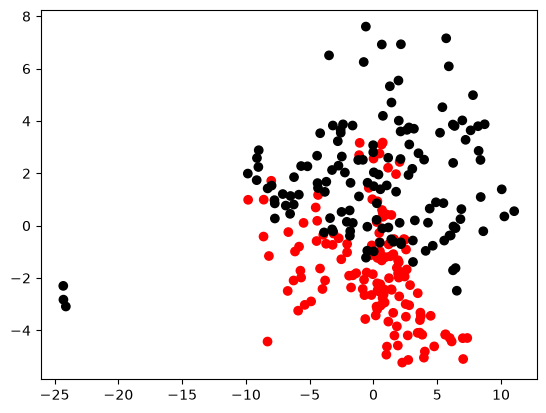

In [15]:
from pursuit import R_pca
from sklearn.decomposition import PCA

mdl = PCA(n_components=2) # this will be used to select the top 2 principal pursuit components

rpca = R_pca(target)
L, S = rpca.fit(max_iter=10000) #L is the low-rank structure we are interested in 
projected_data = mdl.fit_transform(L)
plt.figure()
plt.scatter(*projected_data.T, c=sub_group_labels, cmap=cmap2)

p5 = projected_data.copy()


### Linear Regression + PCA


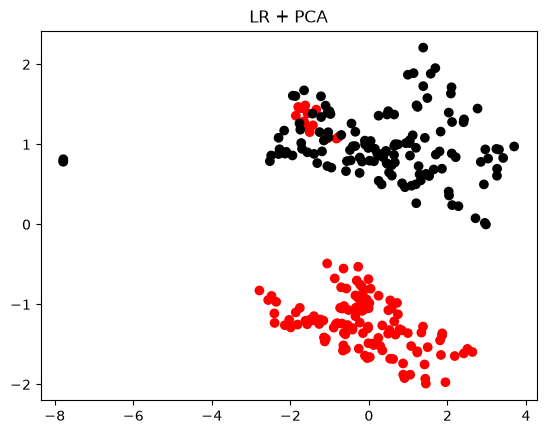

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

lr = LinearRegression()
lr.fit(target, sub_group_labels)
idx = np.where(np.abs(lr.coef_)>0.1)[0] # get significant directions
target_reduced = target[:,idx]
mdl = PCA(n_components=2)
projected_data = mdl.fit_transform(target_reduced)
plt.figure()
plt.scatter(*projected_data.T, c=sub_group_labels, cmap=cmap2)
plt.title('LR + PCA')

p6 = projected_data.copy()


## Combining the 4 methods above into a single figure for pdf report

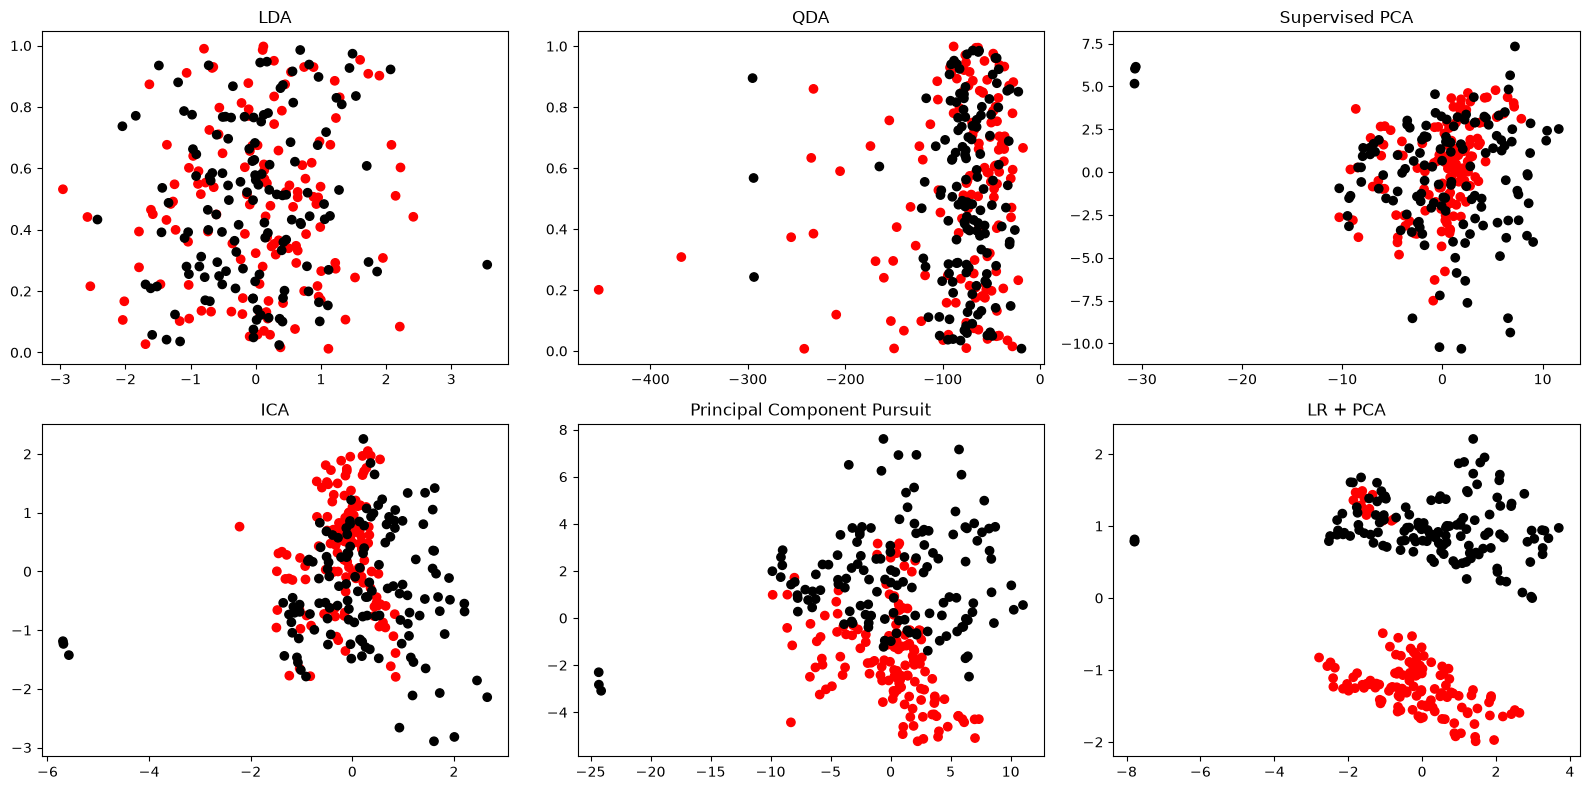

In [18]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax = ax.ravel()

ax[0].scatter(p1.ravel(), y1.ravel(), c=sub_group_labels, cmap=cmap2)
ax[0].set_title('LDA')

ax[1].scatter(p2.ravel(), y2.ravel(), c=sub_group_labels, cmap=cmap2)
ax[1].set_title('QDA')

ax[2].scatter(*p3.T, c=sub_group_labels, cmap=cmap2)
ax[2].set_title('Supervised PCA')

ax[3].scatter(*p4.T, c=sub_group_labels, cmap=cmap2)
ax[3].set_title('ICA')

ax[4].scatter(*p5.T, c=sub_group_labels, cmap=cmap2)
ax[4].set_title('Principal Component Pursuit')

ax[5].scatter(*p6.T, c=sub_group_labels, cmap=cmap2)
ax[5].set_title('LR + PCA')

plt.tight_layout()
plt.show()

### Multidimensional Scaling (MDS)

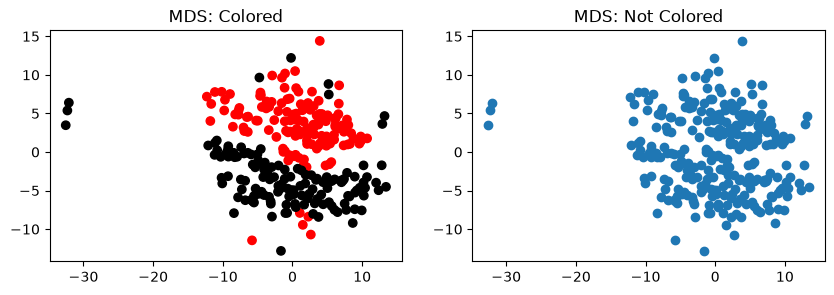

In [11]:
from sklearn.manifold import MDS
np.random.seed(0) # for reproducibility

mdl = MDS(n_components=2)
projected_data = mdl.fit_transform(target)
fig, ax = plt.subplots(1, 2, figsize=(10,3))

ax[0].scatter(*projected_data.T, c=sub_group_labels, cmap=cmap2)
ax[0].set_title('MDS: Colored')

ax[1].scatter(*projected_data.T)
ax[1].set_title('MDS: Not Colored')

plt.show()


MDS is mostly able to separate the subgroups of interest in the mice data, although not as well as cPCA (if the same plot had been plotted without the subgroups colored differently, it would be harder to see the subgroups)

### Factor Analysis

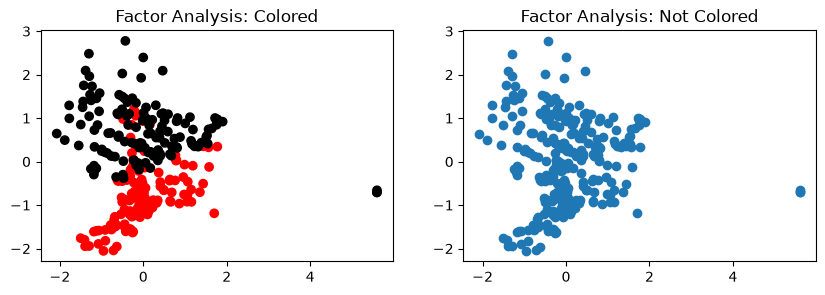

In [12]:
from sklearn.decomposition import FactorAnalysis as FA

mdl = FA(n_components=2)
projected_data = mdl.fit_transform(target)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))

ax[0].scatter(*projected_data.T, c=sub_group_labels, cmap=cmap2)
ax[0].set_title('Factor Analysis: Colored')

ax[1].scatter(*projected_data.T)
ax[1].set_title('Factor Analysis: Not Colored')

plt.show()

FA is unable to resolve the subgroups of interest in the mice data (again, imagine if the subgroups had not been color-coded), although it does a better job than PCA